# Call-type errors: where each encoder goes wrong, and what DAPT changes

**The question.** Domain-adaptive pretraining (DAPT) starts from AVES-bio and keeps pretraining on
zebra finch audio. If specialisation helps, it should help most on the species-specific task, call
type. The board gives one accuracy per model. This notebook opens that number up:

1. **Confusion heatmaps**: which call types each model confuses with which.
2. **What DAPT changed**: per-type recall of DAPT minus its parent AVES-bio, with bird-bootstrap
   intervals.
3. **Confidence**: when the probe is wrong, how sure was it, and was the true type its second
   guess?
4. **Distance to the cluster**: where a misclassified clip sits relative to its own call type's
   centre and to the centre of the type it was called.
5. **Spectrograms** of the errors, next to typical members of both types, plus `show(i)` to look at
   and listen to any clip.
6. **Every DAPT checkpoint, per call type**: does any DAPT recipe help any call type consistently?

**Models (sections 1-5).** AVES-bio, the parent every DAPT run starts from. E23 DAPT
(`daptv4two_2e4s2_step15000`: AVES + 15,000 updates on zebra finch with two-teacher targets, seed 2),
the highest DAPT point on call type. run16, our best from-scratch recipe. Each is read at its own
reported best layer.

**Protocol.** The board's: 3,412 clips, 11 call types, 48 birds; leave-birds-out
StratifiedGroupKFold(5, seed 0); StandardScaler + logistic regression; mean-pooled clip embeddings.
Every prediction is out of fold. Birds are the independent unit, so every interval here is a
bird bootstrap (2,000 resamples, seed 0) and every difference quoted is the observed one.

**Call types** (Elie & Theunissen 2016): Ag = Wsst (aggressive), Be = begging, DC = distance call,
Di = distress, LT = long tonal, Ne = nest, So = song, Te = tet, Th = thuk, Tu = tuck, Wh = whine.
Be and LT are mostly chick calls. Di has 18 clips from 11 birds, so read its intervals before its
bars.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import soundfile as sf
from scipy import signal
from IPython.display import Audio, display
warnings.filterwarnings("ignore")

ANA = Path.home() / "zf_labelset/zf_detection_dataset_v1/analysis"
FEAT = Path.home() / "zf_labelset/zf_detection_dataset_v1/features"
Z = np.load(ANA / "calltype_errors.npz")
classes = [str(c) for c in Z["classes"]]; K = len(classes)
y, birds, paths = Z["y"], Z["birds"], Z["paths"]
TAGS = [str(t) for t in Z["tags"]]
NAME = {"aves-base-bio": "AVES-bio (parent)", "daptv4two_2e4s2_step15000": "E23 DAPT",
        "run16_compute4x": "run16 (scratch)"}
P = {t: Z[f"P__{t}"] for t in TAGS}
R = {t: Z[f"R_lda__{t}"] for t in TAGS}          # decoder-aligned geometry (see section 4)
Rraw = {t: Z[f"R__{t}"] for t in TAGS}
pred = {t: P[t].argmax(1) for t in TAGS}
AV, DA, R16 = TAGS
ORDER = ["DC", "Te", "Ne", "Th", "Tu", "Ag", "Wh", "Di", "So", "Be", "LT"]   # chick-dominant last
oi = [classes.index(c) for c in ORDER]

# palette: sequential blue for magnitude, blue<->red through grey for differences
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e1e0d9"
SEQ = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#a32a29", "#e34948", "#f3b3b2", "#f0efec", "#b7d3f6", "#3987e5", "#184f95"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 9,
                     "axes.edgecolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

# bird bootstrap, shared by every interval below: the same 2,000 resamples of the 48 birds
rng = np.random.default_rng(0)
ub = np.unique(birds); bidx = {b: np.where(birds == b)[0] for b in ub}
BOOT = [np.concatenate([bidx[b] for b in rng.choice(ub, len(ub))]) for _ in range(2000)]

def per_type_recall(hit, idx=None):
    idx = np.arange(len(y)) if idx is None else idx
    n = np.bincount(y[idx], minlength=K); h = np.bincount(y[idx], weights=hit[idx], minlength=K)
    with np.errstate(invalid="ignore"):
        return h / n

def recall_diff(hit_a, hit_b):
    obs = per_type_recall(hit_a) - per_type_recall(hit_b)
    bs = np.array([per_type_recall(hit_a, s) - per_type_recall(hit_b, s) for s in BOOT])
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    oa = hit_a.mean() - hit_b.mean()
    ba = np.array([hit_a[s].mean() - hit_b[s].mean() for s in BOOT])
    return obs, lo, hi, (oa, *np.percentile(ba, [2.5, 97.5]))

for t in TAGS:
    print(f"{NAME[t]:20s} layer {int(Z[f'layer__{t}'])}  accuracy {(pred[t] == y).mean():.4f}  "
          f"errors {(pred[t] != y).sum()} of {len(y)}")
print("\nclips per type:", {c: int((y == classes.index(c)).sum()) for c in ORDER})
print("birds per type:", {c: len(set(birds[y == classes.index(c)])) for c in ORDER})

AVES-bio (parent)    layer 3  accuracy 0.8453  errors 528 of 3412
E23 DAPT             layer 1  accuracy 0.8564  errors 490 of 3412
run16 (scratch)      layer 7  accuracy 0.8379  errors 553 of 3412

clips per type: {'DC': 607, 'Te': 613, 'Ne': 580, 'Th': 290, 'Tu': 240, 'Ag': 195, 'Wh': 172, 'Di': 18, 'So': 192, 'Be': 274, 'LT': 231}
birds per type: {'DC': 26, 'Te': 24, 'Ne': 23, 'Th': 13, 'Tu': 13, 'Ag': 23, 'Wh': 15, 'Di': 11, 'So': 13, 'Be': 15, 'LT': 13}


## 1. Confusion heatmaps

Rows are the true call type, columns what the probe called it; each row sums to 100%. The diagonal
is per-type recall. Off-diagonal cells of 3% or more are labelled.

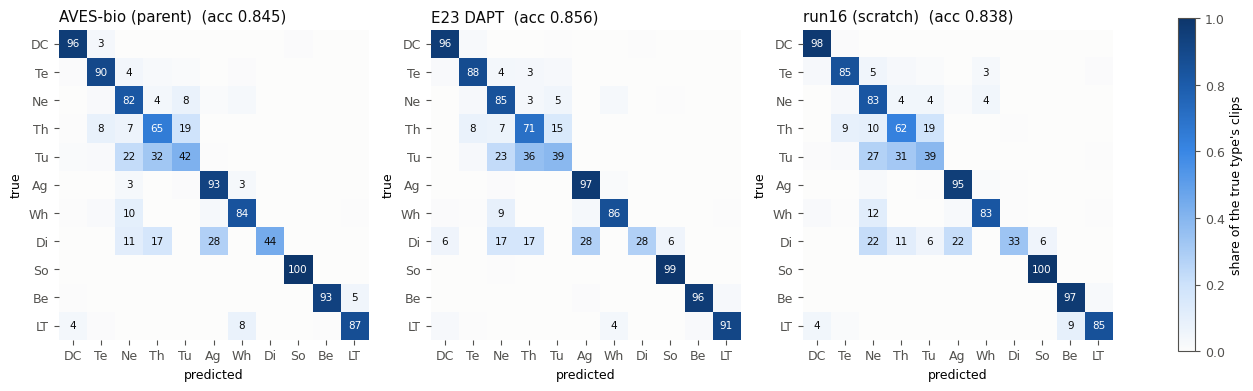

In [2]:
def confusion(t):
    M = np.zeros((K, K)); np.add.at(M, (y, pred[t]), 1)
    return M[np.ix_(oi, oi)]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, t in zip(axes, TAGS):
    M = confusion(t); Mn = M / M.sum(1, keepdims=True)
    im = ax.imshow(Mn, cmap=SEQ, vmin=0, vmax=1)
    for i in range(K):
        for j in range(K):
            if i == j or Mn[i, j] >= 0.03:
                ax.text(j, i, f"{100 * Mn[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                        color="white" if Mn[i, j] > 0.55 else INK)
    ax.set_xticks(range(K)); ax.set_xticklabels(ORDER); ax.set_yticks(range(K)); ax.set_yticklabels(ORDER)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(f"{NAME[t]}  (acc {(pred[t] == y).mean():.3f})", loc="left", color=INK)
    for s in ax.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="share of the true type's clips")
plt.show()

## 2. What DAPT changed, call type by call type

Left: the confusion matrix of E23 DAPT minus AVES-bio's, in percentage points of each true type.
Blue on the diagonal = DAPT recalls that type more often; red off the diagonal = DAPT makes that
particular mistake more often. Right: per-type recall difference with its 95% bird-bootstrap
interval. A bar whose interval crosses zero is not distinguishable from no change.

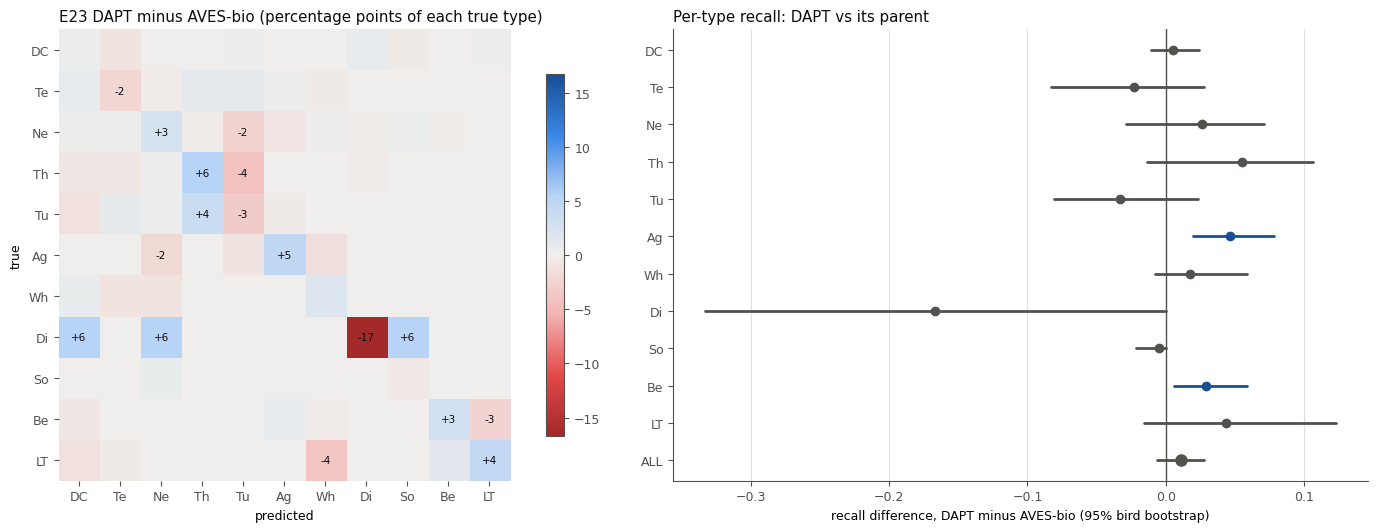

contrast,DAPT - AVES-bio,DAPT - run16
type,,
DC,+0.005,-0.018
Te,-0.023,+0.029
Ne,+0.026,+0.021
Th,+0.055,+0.083
Tu,-0.033,+0.000
Ag,+0.046,+0.021
Wh,+0.017,+0.035
Di,-0.167,-0.056
So,-0.005,-0.005


contrast,type,diff,lo,hi
DAPT - AVES-bio,Ag,+0.046,+0.020,+0.078
DAPT - AVES-bio,Be,+0.029,+0.006,+0.058
DAPT - run16,ALL,+0.018,+0.001,+0.035


In [3]:
hit = {t: (pred[t] == y).astype(float) for t in TAGS}
fig, (a0, a1) = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.05, 1]})
Ma, Md = confusion(AV), confusion(DA)
Dm = 100 * (Md / Md.sum(1, keepdims=True) - Ma / Ma.sum(1, keepdims=True))
lim = np.abs(Dm).max()
im = a0.imshow(Dm, cmap=DIV, vmin=-lim, vmax=lim)
for i in range(K):
    for j in range(K):
        if abs(Dm[i, j]) >= 2:
            a0.text(j, i, f"{Dm[i, j]:+.0f}", ha="center", va="center", fontsize=7.5, color=INK)
a0.set_xticks(range(K)); a0.set_xticklabels(ORDER); a0.set_yticks(range(K)); a0.set_yticklabels(ORDER)
a0.set_xlabel("predicted"); a0.set_ylabel("true")
a0.set_title("E23 DAPT minus AVES-bio (percentage points of each true type)", loc="left", color=INK)
for s in a0.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=a0, shrink=0.8)

rows = []
for other, lab in ((AV, "DAPT - AVES-bio"), (R16, "DAPT - run16")):
    obs, lo, hi, (oa, la, ha) = recall_diff(hit[DA], hit[other])
    for c in ORDER:
        i = classes.index(c)
        rows.append(dict(contrast=lab, type=c, diff=obs[i], lo=lo[i], hi=hi[i],
                         resolved=bool(lo[i] > 0 or hi[i] < 0)))
    rows.append(dict(contrast=lab, type="ALL", diff=oa, lo=la, hi=ha, resolved=bool(la > 0 or ha < 0)))
RD = pd.DataFrame(rows)

d = RD[RD.contrast == "DAPT - AVES-bio"].reset_index(drop=True)
yy = np.arange(len(d))[::-1]
for k, r in d.iterrows():
    col = "#184f95" if (r.resolved and r["diff"] > 0) else "#a32a29" if r.resolved else MUTED
    a1.plot([r.lo, r.hi], [yy[k]] * 2, color=col, lw=2, solid_capstyle="round")
    a1.plot(r["diff"], yy[k], "o", color=col, ms=6 if r.type != "ALL" else 8)
a1.axvline(0, color=MUTED, lw=1)
a1.set_yticks(yy); a1.set_yticklabels(d.type)
a1.set_xlabel("recall difference, DAPT minus AVES-bio (95% bird bootstrap)")
a1.set_title("Per-type recall: DAPT vs its parent", loc="left", color=INK)
a1.xaxis.grid(True, color=GRID); a1.set_axisbelow(True)
plt.tight_layout(); plt.show()
display(RD.pivot(index="type", columns="contrast", values="diff").loc[ORDER + ["ALL"]]
        .style.format("{:+.3f}"))
display(RD[RD.resolved][["contrast", "type", "diff", "lo", "hi"]]
        .style.format({"diff": "{:+.3f}", "lo": "{:+.3f}", "hi": "{:+.3f}"}).hide(axis="index"))

## 3. The mistakes, ranked

The most frequent confusions per model, with how many different birds the errors come from. An
error pattern carried by one or two birds is about those birds' voices, not about the call types.

In [4]:
def top_confusions(t, n=10):
    wrong = pred[t] != y
    df = pd.DataFrame(dict(true=np.array(classes)[y[wrong]], called=np.array(classes)[pred[t][wrong]],
                           bird=birds[wrong]))
    g = df.groupby(["true", "called"]).agg(n=("bird", "size"), birds=("bird", "nunique")).reset_index()
    tot = {c: int((y == classes.index(c)).sum()) for c in classes}
    g["share_of_true"] = g.apply(lambda r: r.n / tot[r.true], axis=1)
    return g.sort_values("n", ascending=False).head(n).reset_index(drop=True)

for t in TAGS:
    print(NAME[t])
    display(top_confusions(t).style.format({"share_of_true": "{:.1%}"}).hide(axis="index"))

AVES-bio (parent)


true,called,n,birds,share_of_true
Tu,Th,77,6,32.1%
Th,Tu,55,11,19.0%
Tu,Ne,54,10,22.5%
Ne,Tu,45,11,7.8%
Te,Ne,24,4,3.9%
Th,Te,24,3,8.3%
Ne,Th,21,9,3.6%
DC,Te,19,6,3.1%
Th,Ne,19,6,6.6%
LT,Wh,18,2,7.8%


E23 DAPT


true,called,n,birds,share_of_true
Tu,Th,86,9,35.8%
Tu,Ne,55,10,22.9%
Th,Tu,43,11,14.8%
Ne,Tu,31,11,5.3%
Te,Ne,22,5,3.6%
Th,Te,22,4,7.6%
Te,Th,21,7,3.4%
Th,Ne,20,5,6.9%
Ne,Th,19,4,3.3%
Ne,Wh,17,9,2.9%


run16 (scratch)


true,called,n,birds,share_of_true
Tu,Th,75,10,31.2%
Tu,Ne,65,10,27.1%
Th,Tu,54,11,18.6%
Te,Ne,29,6,4.7%
Th,Ne,28,10,9.7%
Ne,Tu,26,10,4.5%
Ne,Th,25,7,4.3%
Ne,Wh,25,10,4.3%
Th,Te,25,4,8.6%
LT,Be,21,4,9.1%


## 4. Confidence: how sure was the probe when it was wrong?

Left: the probability the probe gave its own answer, for correct clips and for errors. A probe that
knows when it is unsure puts its errors at low confidence. Right: for the errors, where the true
type ranked among the 11. Rank 2 means the right answer was its second guess, a near miss.

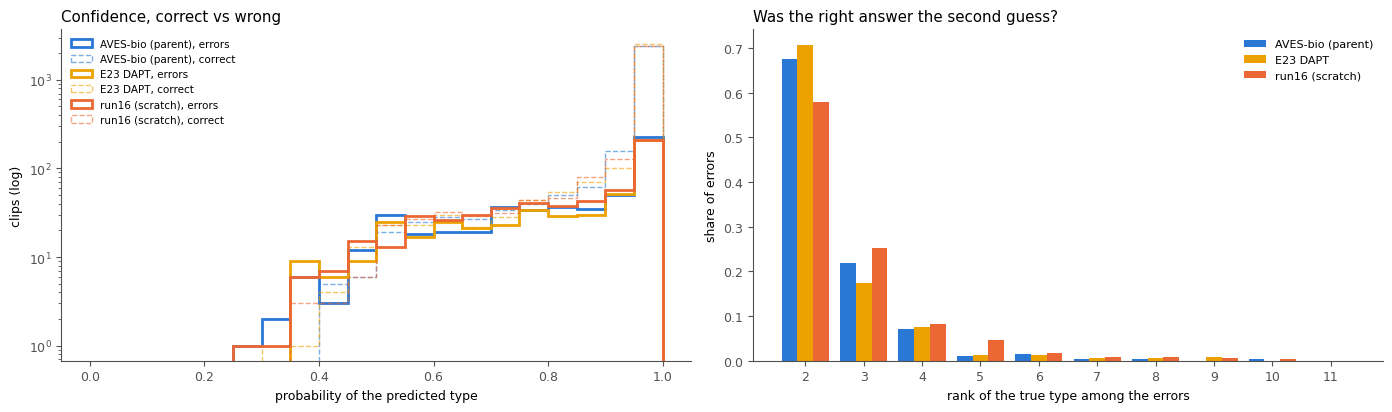

model,errors,median_conf_when_wrong,median_conf_when_right,wrong_with_conf_over_90,true_type_2nd_guess,median_p_true_when_wrong
AVES-bio (parent),528,0.910,0.999,52.1%,67.4%,0.025
E23 DAPT,490,0.916,1.000,53.5%,70.6%,0.033
run16 (scratch),553,0.887,0.999,48.3%,57.9%,0.027


type,DC,Te,Ne,Th,Tu,Ag,Wh,Di,So,Be,LT
errors,23.00,74.00,88.00,85.00,147.00,5.00,24.00,13.00,1.00,10.00,20.00
median confidence,0.77,0.83,0.87,0.95,0.97,0.63,0.93,0.83,0.62,0.83,0.82


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
bins = np.linspace(0, 1, 21)
cols = {AV: "#2a78d6", DA: "#eda100", R16: "#eb6834"}
for t in TAGS:
    conf = P[t].max(1); wrong = pred[t] != y
    axes[0].hist(conf[wrong], bins=bins, histtype="step", lw=2, color=cols[t], label=f"{NAME[t]}, errors")
    axes[0].hist(conf[~wrong], bins=bins, histtype="step", lw=1, ls="--", color=cols[t],
                 label=f"{NAME[t]}, correct", density=False, alpha=0.6)
axes[0].set_yscale("log"); axes[0].set_xlabel("probability of the predicted type"); axes[0].set_ylabel("clips (log)")
axes[0].legend(fontsize=7.5, frameon=False); axes[0].set_title("Confidence, correct vs wrong", loc="left")

ranks = {}
for t in TAGS:
    wrong = np.where(pred[t] != y)[0]
    order = np.argsort(-P[t][wrong], axis=1)
    ranks[t] = np.array([int(np.where(o == y[i])[0][0]) + 1 for o, i in zip(order, wrong)])
w = 0.27
for k, t in enumerate(TAGS):
    cnt = np.bincount(ranks[t], minlength=12)[2:12]
    axes[1].bar(np.arange(2, 12) + (k - 1) * w, cnt / len(ranks[t]), width=w, color=cols[t], label=NAME[t])
axes[1].set_xticks(range(2, 12)); axes[1].set_xlabel("rank of the true type among the errors")
axes[1].set_ylabel("share of errors"); axes[1].legend(fontsize=8, frameon=False)
axes[1].set_title("Was the right answer the second guess?", loc="left")
plt.tight_layout(); plt.show()

rows = []
for t in TAGS:
    wrong = pred[t] != y; conf = P[t].max(1); ptrue = P[t][np.arange(len(y)), y]
    rows.append(dict(model=NAME[t], errors=int(wrong.sum()),
                     median_conf_when_wrong=np.median(conf[wrong]),
                     median_conf_when_right=np.median(conf[~wrong]),
                     wrong_with_conf_over_90=float((conf[wrong] > 0.9).mean()),
                     true_type_2nd_guess=float((ranks[t] == 2).mean()),
                     median_p_true_when_wrong=np.median(ptrue[wrong])))
display(pd.DataFrame(rows).style.format({c: "{:.3f}" for c in
        ["median_conf_when_wrong", "median_conf_when_right", "median_p_true_when_wrong"]} |
        {"wrong_with_conf_over_90": "{:.1%}", "true_type_2nd_guess": "{:.1%}"}).hide(axis="index"))

# per type, for DAPT: how confident are the errors of each type
wrong = pred[DA] != y; conf = P[DA].max(1)
pt = pd.DataFrame(dict(type=np.array(classes)[y], wrong=wrong, conf=conf))
display(pt[pt.wrong].groupby("type").conf.agg(["size", "median"]).loc[[c for c in ORDER if c in set(pt[pt.wrong].type)]]
        .rename(columns={"size": "errors", "median": "median confidence"}).T.style.format("{:.2f}"))

## 5. Distance to the call-type cluster

For each clip, the distance to the centre of every call type, computed out of fold (centres and
scales from the training birds only). Distances are in units of each type's own spread: **1.0 = as
far from the centre as a typical member of that type**.

Two geometries are measured:

- **Raw**: the standardised embedding itself. This is the geometry a label-free clustering would
  see.
- **Decoder-aligned**: a 10-dimensional shrinkage-LDA space fitted on the training fold, the
  directions that separate call types. This is closer to what the probe uses.

The first table is the sanity check: nearest-centroid accuracy in each geometry, against the
probe. The gap between raw and LDA is how much of the call-type structure is *not* visible as
clusters in the raw embedding.

model,probe,nearest_centroid_raw,nearest_centroid_lda
AVES-bio (parent),0.8453,0.6187,0.7699
E23 DAPT,0.8564,0.6190,0.7987
run16 (scratch),0.8379,0.6222,0.7122


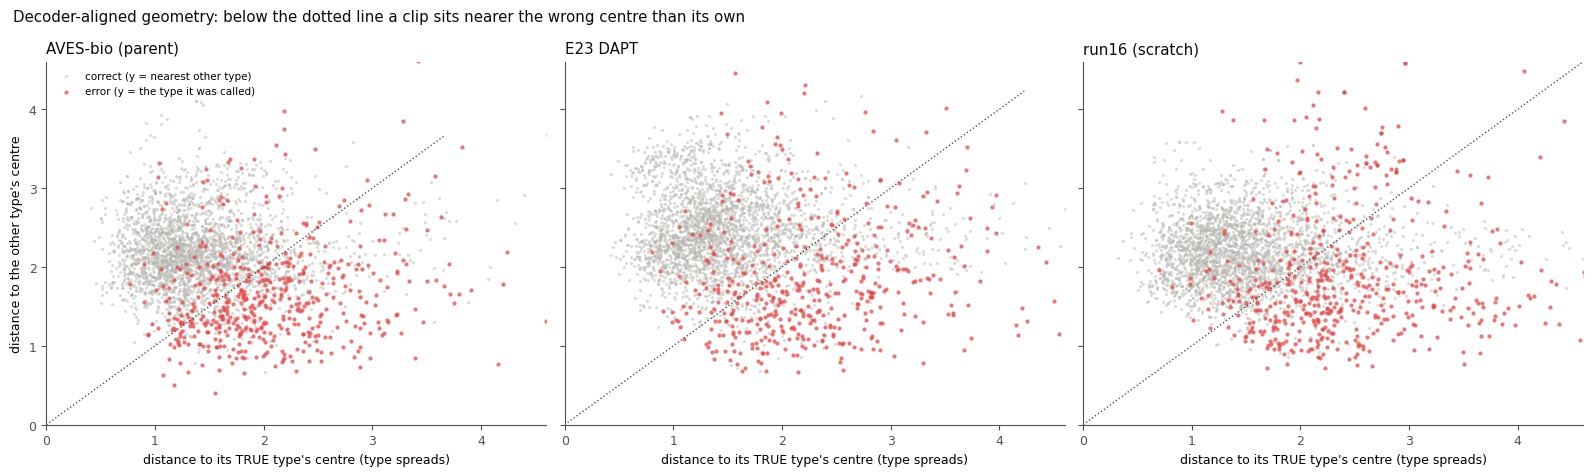

model,median_dist_to_own_centre_correct,median_dist_to_own_centre_errors,errors_inside_called_type,errors_still_inside_own_type
AVES-bio (parent),1.31,1.99,9.8%,1.3%
E23 DAPT,1.38,2.19,7.8%,1.2%
run16 (scratch),1.43,2.30,5.8%,0.9%


'inside' = within the typical spread (distance < 1) of that type's centre, decoder-aligned geometry


In [6]:
rows = []
for t in TAGS:
    rows.append(dict(model=NAME[t], probe=(pred[t] == y).mean(),
                     nearest_centroid_raw=(Rraw[t].argmin(1) == y).mean(),
                     nearest_centroid_lda=(R[t].argmin(1) == y).mean()))
display(pd.DataFrame(rows).style.format({c: "{:.4f}" for c in
        ["probe", "nearest_centroid_raw", "nearest_centroid_lda"]}).hide(axis="index"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharex=True, sharey=True)
for ax, t in zip(axes, TAGS):
    i = np.arange(len(y)); wrong = pred[t] != y
    rt = R[t][i, y]; rp = R[t][i, pred[t]]
    # for correct clips the predicted type IS the true type; use their nearest OTHER type instead
    Ro = R[t].copy(); Ro[i, y] = np.inf; ro = Ro.min(1)
    ax.scatter(rt[~wrong], ro[~wrong], s=5, color="#b9b8b3", alpha=0.5, lw=0, label="correct (y = nearest other type)")
    ax.scatter(rt[wrong], rp[wrong], s=9, color="#e34948", alpha=0.75, lw=0, label="error (y = the type it was called)")
    m = max(np.percentile(rt, 99), np.percentile(ro, 99))
    ax.plot([0, m], [0, m], color=MUTED, lw=1, ls=":")
    ax.set_xlim(0, m); ax.set_ylim(0, m)
    ax.set_xlabel("distance to its TRUE type's centre (type spreads)")
    ax.set_title(NAME[t], loc="left", color=INK)
axes[0].set_ylabel("distance to the other type's centre")
axes[0].legend(fontsize=7.5, frameon=False, loc="upper left")
fig.suptitle("Decoder-aligned geometry: below the dotted line a clip sits nearer the wrong centre than its own",
             x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.show()

rows = []
for t in TAGS:
    i = np.arange(len(y)); wrong = pred[t] != y
    rt = R[t][i, y]; rp = R[t][i, pred[t]]
    rows.append(dict(model=NAME[t],
                     median_dist_to_own_centre_correct=np.median(rt[~wrong]),
                     median_dist_to_own_centre_errors=np.median(rt[wrong]),
                     errors_inside_called_type=float((rp[wrong] < 1).mean()),
                     errors_still_inside_own_type=float((rt[wrong] < 1).mean())))
display(pd.DataFrame(rows).style.format({"median_dist_to_own_centre_correct": "{:.2f}",
        "median_dist_to_own_centre_errors": "{:.2f}", "errors_inside_called_type": "{:.1%}",
        "errors_still_inside_own_type": "{:.1%}"}).hide(axis="index"))
print("'inside' = within the typical spread (distance < 1) of that type's centre, decoder-aligned geometry")

## 6. What the mistakes look and sound like

For E23 DAPT's four most frequent confusions, each row shows:

- two **typical** clips of the true type (correct, nearest its centre);
- the four most **confident** errors (true type → called type);
- two typical clips of the type it was called.

Spectrograms run 0-10 kHz, each clip on its own time axis. Titles give the bird, the probe's
probability for the type it chose, and the distance to the true type's centre.

To look at and listen to any clip, call `show(i)` with its row number (printed in the titles).

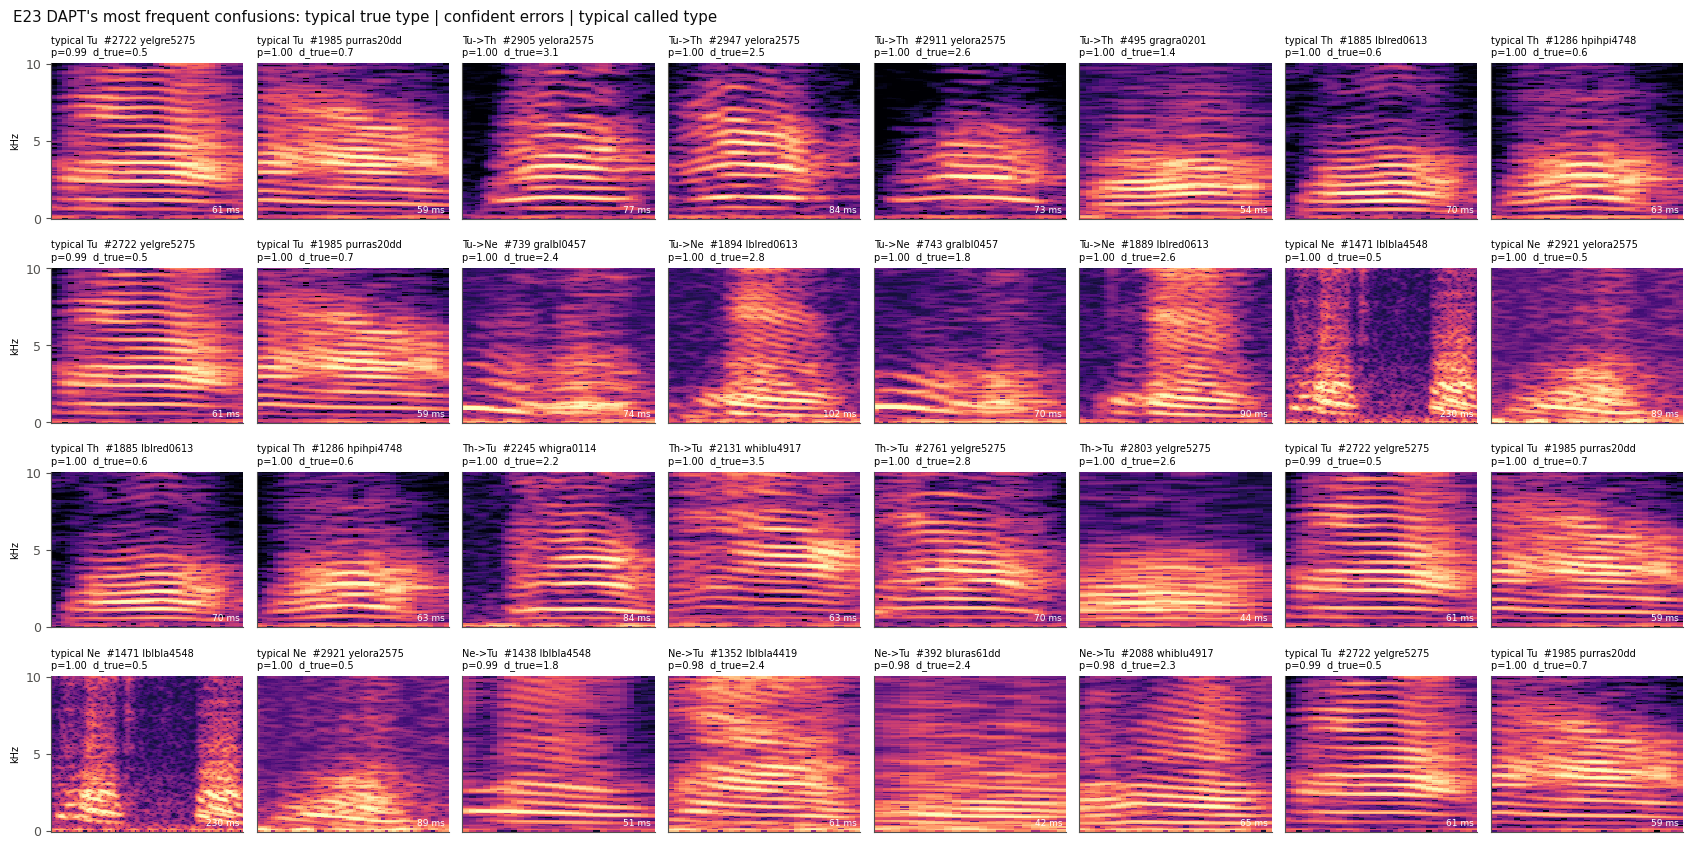

In [7]:
def spec(path, fmax=10000):
    w, sr = sf.read(path, always_2d=True); w = w.mean(1)
    f, tt, S = signal.spectrogram(w, sr, nperseg=512, noverlap=448, window="hann")
    k = f <= fmax
    return tt, f[k], 10 * np.log10(S[k] + 1e-12), len(w) / sr

def draw(ax, i, t=DA, title=None):
    tt, f, S, dur = spec(paths[i])
    vmax = np.percentile(S, 99.5)
    ax.pcolormesh(tt, f / 1000, S, cmap="magma", vmin=vmax - 55, vmax=vmax, shading="auto")
    ax.set_xticks([]); ax.set_yticks([0, 5, 10] if ax.get_subplotspec().is_first_col() else [])
    ax.set_title(title or f"#{i} {birds[i]}", fontsize=7, loc="left")
    ax.text(0.98, 0.04, f"{1000 * dur:.0f} ms", transform=ax.transAxes, ha="right", fontsize=6.5, color="white")

def typical(c, t=DA, n=2):
    i = np.where((y == c) & (pred[t] == y))[0]
    return i[np.argsort(R[t][i, c])[:n]]

g = top_confusions(DA, 4)
fig, axes = plt.subplots(len(g), 8, figsize=(17, 2.0 * len(g) + 0.6))
for r, row in g.iterrows():
    ct, cp = classes.index(row.true), classes.index(row.called)
    errs = np.where((y == ct) & (pred[DA] == cp))[0]
    errs = errs[np.argsort(-P[DA][errs, cp])[:4]]
    cells = [(i, f"typical {row.true}") for i in typical(ct)] + \
            [(i, f"{row.true}->{row.called}") for i in errs] + \
            [(i, f"typical {row.called}") for i in typical(cp)]
    for k, ax in enumerate(axes[r]):
        if k >= len(cells):
            ax.axis("off"); continue
        i, lab = cells[k]
        draw(ax, i, title=f"{lab}  #{i} {birds[i]}\np={P[DA][i].max():.2f}  d_true={R[DA][i, y[i]]:.1f}")
    axes[r][0].set_ylabel("kHz", fontsize=7)
fig.suptitle("E23 DAPT's most frequent confusions: typical true type | confident errors | typical called type",
             x=0.01, ha="left", color=INK)
plt.tight_layout(); plt.show()

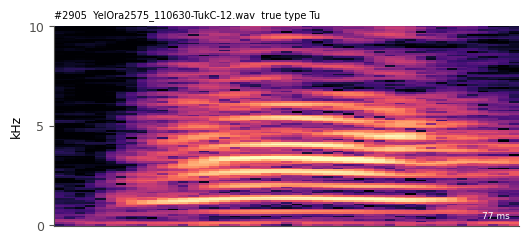

model,called,top3,p_true,d_true,d_called
AVES-bio (parent),Th,"Th 1.00, Tu 0.00, Di 0.00",0.000,2.88,0.99
E23 DAPT,Th,"Th 1.00, Te 0.00, DC 0.00",0.000,3.13,1.41
run16 (scratch),Th,"Th 1.00, Ne 0.00, Tu 0.00",0.000,2.77,1.34


In [8]:
def show(i):
    # spectrogram, audio, and what every model made of clip i
    fig, ax = plt.subplots(figsize=(6, 2.6))
    draw(ax, i, title=f"#{i}  {Path(paths[i]).name}  true type {classes[y[i]]}")
    ax.set_ylabel("kHz"); plt.show()
    w, sr = sf.read(paths[i], always_2d=True)
    display(Audio(w.mean(1), rate=sr))
    rows = []
    for t in TAGS:
        top = np.argsort(-P[t][i])[:3]
        rows.append(dict(model=NAME[t], called=classes[top[0]],
                         top3=", ".join(f"{classes[c]} {P[t][i, c]:.2f}" for c in top),
                         p_true=P[t][i, y[i]], d_true=R[t][i, y[i]], d_called=R[t][i, top[0]]))
    display(pd.DataFrame(rows).style.format({"p_true": "{:.3f}", "d_true": "{:.2f}",
                                             "d_called": "{:.2f}"}).hide(axis="index"))

# example: DAPT's single most confident error
wrong = np.where(pred[DA] != y)[0]
show(int(wrong[np.argmax(P[DA][wrong].max(1))]))

## 7. Errors every model makes, and errors DAPT fixed or introduced

Clips all three encoders get wrong, with high confidence, are candidates for ambiguous calls or
label errors rather than model failures. Clips that AVES-bio gets wrong and DAPT gets right (and
the reverse) are where DAPT's change actually lives.

all three wrong: 239 clips (28 birds); of those, all three agree on the same wrong type: 176
DAPT fixed (AVES wrong, DAPT right): 201   DAPT broke (AVES right, DAPT wrong): 163   net +38


,DC,Te,Ne,Th,Tu,Ag,Wh,Di,So,Be,LT
fixed,9,29,53,41,28,10,8,0,0,9,14
broke,6,43,38,25,36,1,5,3,1,1,4
net,3,-14,15,16,-8,9,3,-3,-1,8,10


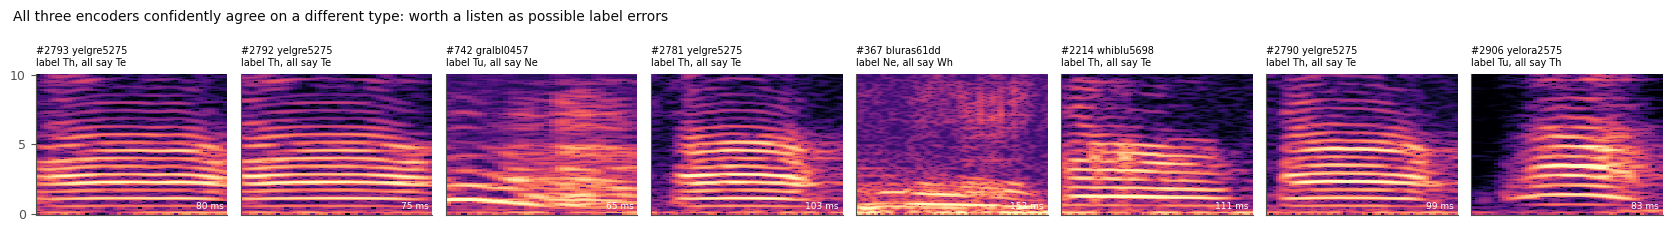

In [9]:
W = {t: pred[t] != y for t in TAGS}
allw = W[AV] & W[DA] & W[R16]
fixed = W[AV] & ~W[DA]; broke = ~W[AV] & W[DA]
print(f"all three wrong: {allw.sum()} clips ({len(set(birds[allw]))} birds); "
      f"of those, all three agree on the same wrong type: "
      f"{(allw & (pred[AV] == pred[DA]) & (pred[DA] == pred[R16])).sum()}")
print(f"DAPT fixed (AVES wrong, DAPT right): {fixed.sum()}   DAPT broke (AVES right, DAPT wrong): {broke.sum()}"
      f"   net {fixed.sum() - broke.sum():+d}")
tab = pd.DataFrame({"fixed": pd.Series(np.array(classes)[y[fixed]]).value_counts(),
                    "broke": pd.Series(np.array(classes)[y[broke]]).value_counts()}).fillna(0).astype(int)
tab["net"] = tab.fixed - tab.broke
display(tab.reindex(ORDER).fillna(0).astype(int).T)

agree = np.where(allw & (pred[AV] == pred[DA]) & (pred[DA] == pred[R16]))[0]
agree = agree[np.argsort(-np.minimum.reduce([P[t][agree].max(1) for t in TAGS]))][:8]
if len(agree):
    fig, axes = plt.subplots(1, len(agree), figsize=(2.1 * len(agree), 2.3))
    for ax, i in zip(np.atleast_1d(axes), agree):
        draw(ax, i, title=f"#{i} {birds[i]}\nlabel {classes[y[i]]}, all say {classes[pred[DA][i]]}")
    fig.suptitle("All three encoders confidently agree on a different type: worth a listen as possible label errors",
                 x=0.01, ha="left", fontsize=10, color=INK)
    plt.tight_layout(); plt.show()

## 8. Every DAPT checkpoint, call type by call type

Sections 1-7 use one DAPT run. The real question is whether *any* way of continuing AVES on zebra
finch moves call type, and whether different DAPT runs move the *same* call types. A type that
improves in one seed and not in its replicate is noise.

Each row is a DAPT checkpoint, read at its own reported best layer exactly as the board does. Each
cell is its recall minus its parent's on that call type (AVES-bio; BirdAVES biox-base for E14); a
dot marks a 95% bird-bootstrap interval that excludes zero. The rightmost column is overall
accuracy.

The rows are not independent replications. They share a parent and most share a recipe, and 11
types times many rows is a lot of tests. Read a column as a pattern only if it holds across
different recipes *and* across the seed pairs (E19/E23, E21/E24, E18/E20).

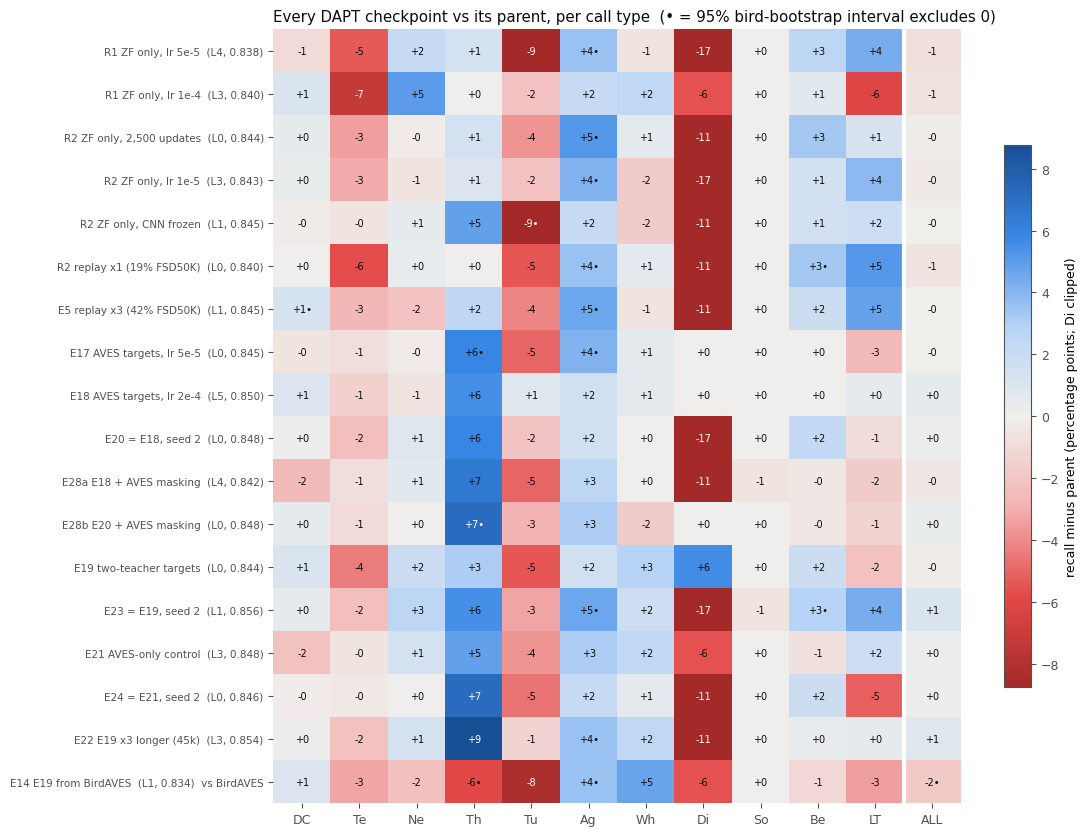

18 DAPT checkpoints. Overall accuracy vs parent resolved: 1 (up 0, down 1)


,DC,Te,Ne,Th,Tu,Ag,Wh,Di,So,Be,LT,ALL
higher than parent (point),11,0,10,15,1,18,11,1,0,12,10,7
lower than parent (point),6,18,6,1,17,0,5,14,2,4,8,11
"higher, resolved",1,0,0,2,0,9,0,0,0,2,0,0
"lower, resolved",0,0,0,1,1,0,0,0,0,0,0,1


,DC,Te,Ne,Th,Tu,Ag,Wh,Di,So,Be,LT,ALL
median diff,+0.002,-0.023,+0.004,+0.048,-0.040,+0.033,+0.006,-0.111,+0.000,+0.015,+0.004,-0.000


In [10]:
import sys
sys.path.insert(0, str(Path.cwd().parent / "zfeval/experiments")); sys.path.insert(0, str(Path.cwd().parent / "zfeval"))
from aves_calltype import cv_acc

AVJ = json.loads((ANA / "aves_variants_calltype.json").read_text())["models"]
def reported(tag):
    if tag in AVJ:
        return AVJ[tag]["best_11"]["layer"], AVJ[tag]["best_11"]["acc"]
    p = ANA / f"{tag}_calltype.json"
    if not p.exists():
        return None
    d = json.loads(p.read_text())
    return d["best_layer11"], d["acc11"]

def oof_hit(tag):
    layer, acc_rep = reported(tag)
    f = {"aves-base-bio": "ct11_aves_emb.npy"}.get(tag, f"ct11_{tag}_emb.npy")
    X = np.ascontiguousarray(np.load(FEAT / f, mmap_mode="r")[:, layer])
    a, _, Pt = cv_acc(X, y, birds, return_proba=True)
    assert abs(a - acc_rep) < 1e-9, (tag, a, acc_rep)
    return (Pt.argmax(1) == y).astype(float), layer, a

# readable names, grouped by round; experiment ids from harness/experiments.yaml
LABEL = {
    "dapt5e5_step15000": "R1 ZF only, lr 5e-5", "dapt1e4_step15000": "R1 ZF only, lr 1e-4",
    "daptshort_5e5_step2500": "R2 ZF only, 2,500 updates", "daptlr_1e5_step15000": "R2 ZF only, lr 1e-5",
    "daptfreeze_5e5_step15000": "R2 ZF only, CNN frozen",
    "daptreplay_5e5_step15000": "R2 replay x1 (19% FSD50K)", "daptreplay3_5e5_step15000": "E5 replay x3 (42% FSD50K)",
    "daptv3aves_5e5_step15000": "E17 AVES targets, lr 5e-5", "daptv3aves_2e4_step15000": "E18 AVES targets, lr 2e-4",
    "daptv3aves_2e4s2_step15000": "E20 = E18, seed 2", "daptv3aves_2e4m8_step15000": "E28a E18 + AVES masking",
    "daptv3aves_2e4s2m8_step15000": "E28b E20 + AVES masking",
    "daptv4two_2e4_step15000": "E19 two-teacher targets", "daptv4two_2e4s2_step15000": "E23 = E19, seed 2",
    "daptv4aveso_2e4_step15000": "E21 AVES-only control", "daptv4aveso_2e4s2_step15000": "E24 = E21, seed 2",
    "daptv4two45k_2e4_step45000": "E22 E19 x3 longer (45k)", "daptv4bird_2e4_step15000": "E14 E19 from BirdAVES",
}
PARENT = {t: "aves-base-bio" for t in LABEL}
PARENT["daptv4bird_2e4_step15000"] = "birdaves-biox-base"      # E14 starts from BirdAVES, not AVES-bio

dapt = [t for t in LABEL if (FEAT / f"ct11_{t}_emb.npy").exists() and reported(t)]
missing = [t for t in LABEL if t not in dapt]
parent_hit = {p: oof_hit(p)[0] for p in set(PARENT[t] for t in dapt)}
rows, sig, info = [], [], {}
for t in dapt:
    h, layer, a = oof_hit(t)
    obs, lo, hi, (oa, la, ha) = recall_diff(h, parent_hit[PARENT[t]])
    rows.append(list(obs[oi]) + [oa])
    sig.append([bool(lo[i] > 0 or hi[i] < 0) for i in oi] + [bool(la > 0 or ha < 0)])
    info[t] = (layer, a)
H = pd.DataFrame(rows, index=dapt, columns=ORDER + ["ALL"])
S = pd.DataFrame(sig, index=dapt, columns=ORDER + ["ALL"])
if missing:
    print("not scored on call type yet:", missing)

fig, ax = plt.subplots(figsize=(11.5, 0.38 * len(H) + 1.6))
lim = 100 * np.nanmax(np.abs(H.drop(columns=["Di", "ALL"]).values))   # Di (18 clips) would set the scale alone
im = ax.imshow(np.clip(100 * H.values, -lim, lim), cmap=DIV, vmin=-lim, vmax=lim, aspect="auto")
for r in range(H.shape[0]):
    for c in range(H.shape[1]):
        v = 100 * H.values[r, c]
        ax.text(c, r, f"{v:+.0f}" + ("\u2022" if S.values[r, c] else ""), ha="center", va="center",
                fontsize=7, color="white" if abs(v) > 0.8 * lim else INK)
ax.set_xticks(range(H.shape[1])); ax.set_xticklabels(H.columns)
ax.set_yticks(range(H.shape[0]))
ax.set_yticklabels([f"{LABEL[t]}  (L{info[t][0]}, {info[t][1]:.3f})" + ("  vs BirdAVES" if PARENT[t] != "aves-base-bio" else "")
                    for t in H.index], fontsize=7.5)
ax.axvline(len(ORDER) - 0.5, color="white", lw=3)
fig.colorbar(im, ax=ax, shrink=0.7, label="recall minus parent (percentage points; Di clipped)")
ax.set_title("Every DAPT checkpoint vs its parent, per call type  (\u2022 = 95% bird-bootstrap interval excludes 0)",
             loc="left", color=INK)
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

print(f"{len(H)} DAPT checkpoints. Overall accuracy vs parent resolved: {int(S['ALL'].sum())} "
      f"(up {int((S['ALL'] & (H['ALL'] > 0)).sum())}, down {int((S['ALL'] & (H['ALL'] < 0)).sum())})")
cons = pd.DataFrame({"higher than parent (point)": (H > 0).sum(), "lower than parent (point)": (H < 0).sum(),
                     "higher, resolved": (S & (H > 0)).sum(), "lower, resolved": (S & (H < 0)).sum()}).T
display(cons[ORDER + ["ALL"]])
display(pd.DataFrame({"median diff": H.median()}).T[ORDER + ["ALL"]].style.format("{:+.3f}"))

## 9. Does specialising longer help call type? The round-1 trajectories

Round 1 continued AVES-bio on zebra finch audio only, saving a checkpoint every 2,500 updates at two
learning rates. These checkpoints were scored for detection (notebook 03) but never for call type
until now. If specialisation helps call type, accuracy should rise with steps on zebra finch.
Each point is the checkpoint minus AVES-bio (observed difference, 95% bird bootstrap, from
`<tag>_bootstrap.json`), at its own best layer (left) and at the fixed layer 3 (right; no layer
selection).

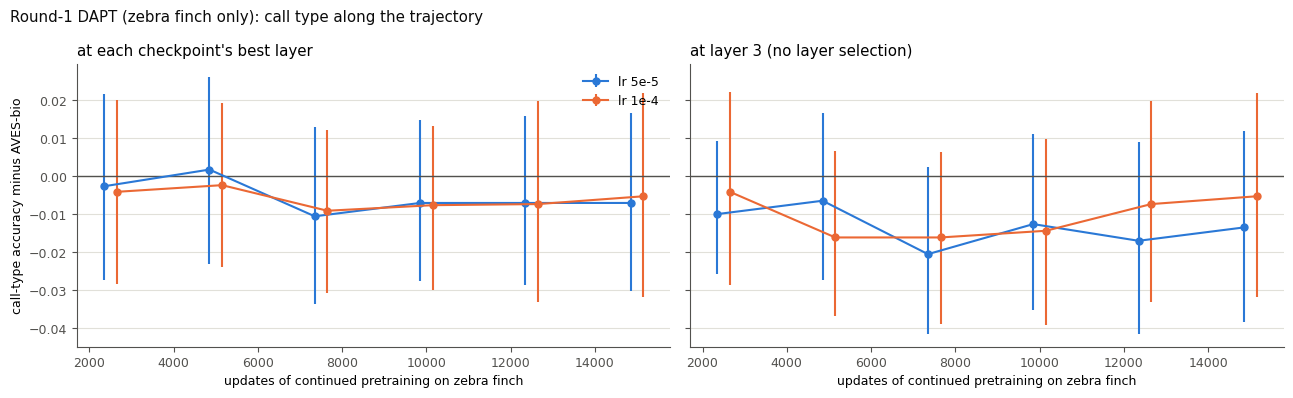

lr,step,best_layer_diff,lo,hi,L3_diff,L3_lo,L3_hi
5e5,2500,-0.0026,-0.0272,+0.0217,-0.0100,-0.0257,+0.0092
5e5,5000,+0.0018,-0.0230,+0.0262,-0.0064,-0.0274,+0.0166
5e5,7500,-0.0106,-0.0337,+0.0131,-0.0205,-0.0415,+0.0026
5e5,10000,-0.0070,-0.0276,+0.0148,-0.0126,-0.0352,+0.0112
5e5,12500,-0.0070,-0.0287,+0.0159,-0.0170,-0.0415,+0.0090
5e5,15000,-0.0070,-0.0303,+0.0168,-0.0135,-0.0384,+0.0119
1e4,2500,-0.0041,-0.0284,+0.0201,-0.0041,-0.0287,+0.0222
1e4,5000,-0.0023,-0.0238,+0.0193,-0.0161,-0.0369,+0.0068
1e4,7500,-0.0091,-0.0308,+0.0122,-0.0161,-0.0388,+0.0063
1e4,10000,-0.0076,-0.0299,+0.0133,-0.0144,-0.0391,+0.0099


In [11]:
traj = {}
for lr in ("5e5", "1e4"):
    for step in (2500, 5000, 7500, 10000, 12500, 15000):
        t = f"dapt{lr}_step{step}"
        p = ANA / f"{t}_bootstrap.json"
        if p.exists():
            v = json.loads(p.read_text())["vs"]
            traj.setdefault(lr, []).append((step, v[t]["aves-base-bio"], v[f"{t}@L3"]["aves-base-bio"]))
if not traj:
    print("no round-1 checkpoint has been scored on call type yet")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
    col = {"5e5": "#2a78d6", "1e4": "#eb6834"}
    for k, ax in enumerate(axes):
        for lr, pts in traj.items():
            st = np.array([p[0] for p in pts]) + (-150 if lr == "5e5" else 150)
            d = [p[1 + k] for p in pts]
            ax.errorbar(st, [x["delta"] for x in d],
                        yerr=[[x["delta"] - x["lo"] for x in d], [x["hi"] - x["delta"] for x in d]],
                        fmt="o-", color=col[lr], lw=1.5, ms=5, capsize=0, label=f"lr {lr.replace('e', 'e-')}")
        ax.axhline(0, color=MUTED, lw=1)
        ax.set_xlabel("updates of continued pretraining on zebra finch")
        ax.set_title(["at each checkpoint's best layer", "at layer 3 (no layer selection)"][k], loc="left")
        ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
    axes[0].set_ylabel("call-type accuracy minus AVES-bio"); axes[0].legend(frameon=False)
    fig.suptitle("Round-1 DAPT (zebra finch only): call type along the trajectory", x=0.01, ha="left", color=INK)
    plt.tight_layout(); plt.show()
    rows = [dict(lr=lr, step=p[0], best_layer_diff=p[1]["delta"], lo=p[1]["lo"], hi=p[1]["hi"],
                 L3_diff=p[2]["delta"], L3_lo=p[2]["lo"], L3_hi=p[2]["hi"]) for lr, pts in traj.items() for p in pts]
    display(pd.DataFrame(rows).style.format({c: "{:+.4f}" for c in
            ["best_layer_diff", "lo", "hi", "L3_diff", "L3_lo", "L3_hi"]}).hide(axis="index"))

**Reading the trajectories.** Continuing AVES-bio on zebra finch audio alone never raised call type,
at any of the 12 checkpoints or either learning rate. The point estimates sit at or below the parent
throughout, more clearly at the fixed layer 3 than at each checkpoint's own best layer. No single
checkpoint is resolved from the parent, and there is no rising trend to extend. More specialisation
on the same audio is not the road to a call-type gain.

## 10. Where the headroom is

One cell that collects the numbers the conclusions rest on: how the errors are spread over call
types, and how close the best frozen probes are to what supervised fine-tuning reaches on the same
folds (`finetune_calltype.json`: the whole encoder trained on the call-type labels, 2 seeds).

In [12]:
soft = ["Te", "Ne", "Th", "Tu"]
si = [classes.index(c) for c in soft]
for t in TAGS:
    w = pred[t] != y
    print(f"{NAME[t]:20s} {w.sum()} errors; {np.isin(y[w], si).mean():.0%} of them are true {'/'.join(soft)} "
          f"(these types are {np.isin(y, si).mean():.0%} of the clips); recall on Tu {per_type_recall(hit[t])[classes.index('Tu')]:.2f}")
FT = json.loads((ANA / "finetune_calltype.json").read_text())["summary"]["arms"]
ft = FT["full_ft"]["aves"]
print(f"\nAVES-bio fully fine-tuned on call type: {ft['mean']:.4f} (seeds: "
      + ", ".join(f"{v:.4f}" for v in ft["per_seed_mean"].values())
      + f"); same-script frozen layer 3: {FT['frozen_L3']['aves']['mean']:.4f}")
print("note: finetune_calltype.json averages accuracy over folds, the board pools clips; the two differ slightly")
print(f"best frozen points on the board: E23 DAPT {(pred[DA] == y).mean():.4f}, AVES-bio {(pred[AV] == y).mean():.4f}")

AVES-bio (parent)    528 errors; 76% of them are true Te/Ne/Th/Tu (these types are 50% of the clips); recall on Tu 0.42
E23 DAPT             490 errors; 80% of them are true Te/Ne/Th/Tu (these types are 50% of the clips); recall on Tu 0.39
run16 (scratch)      553 errors; 81% of them are true Te/Ne/Th/Tu (these types are 50% of the clips); recall on Tu 0.39

AVES-bio fully fine-tuned on call type: 0.8600 (seeds: 0.8607, 0.8594); same-script frozen layer 3: 0.8429
note: finetune_calltype.json averages accuracy over folds, the board pools clips; the two differ slightly
best frozen points on the board: E23 DAPT 0.8564, AVES-bio 0.8453


## 11. Are the soft-call errors about the calls, or about new birds?

Every number above is leave-birds-out: the probe never heard the test bird. Here the same
embeddings are probed with a random clip split (StratifiedKFold(5), seed 0), so the test birds'
other calls are in training. A call type whose recall jumps under the random split is
confused because birds say it differently, not because the type is acoustically ambiguous.
(A random split lets the probe learn each test bird's voice and inflates call type; the 2023
AVES notebook used one, finding 034. It is used here only as a diagnostic, never as a score.)

In [13]:
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def random_split_pred(tag):
    f = {"aves-base-bio": "ct11_aves_emb.npy"}.get(tag, f"ct11_{tag}_emb.npy")
    X = np.ascontiguousarray(np.load(FEAT / f, mmap_mode="r")[:, int(Z[f"layer__{tag}"])])
    p = np.zeros(len(y), int)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=0).split(X, y):
        p[te] = make_pipeline(StandardScaler(), LogisticRegression(max_iter=4000)).fit(X[tr], y[tr]).predict(X[te])
    return p

rows = {}
for t in (AV, DA):
    pr = random_split_pred(t)
    rows[(NAME[t], "random split")] = list(per_type_recall((pr == y).astype(float))[oi]) + [(pr == y).mean()]
    rows[(NAME[t], "leave birds out")] = list(per_type_recall(hit[t])[oi]) + [hit[t].mean()]
RS = pd.DataFrame(rows, index=ORDER + ["ALL"]).T
display(RS.style.format("{:.2f}").background_gradient(cmap=SEQ, vmin=0.3, vmax=1, axis=None))
for m in (NAME[AV], NAME[DA]):
    gap = RS.loc[(m, "random split")] - RS.loc[(m, "leave birds out")]
    print(f"{m:18s} recall lost to new birds: " + "  ".join(f"{c} {gap[c]:+.2f}" for c in ["Tu", "Th", "Ne", "Te", "ALL"]))
d_rand = RS.loc[(NAME[DA], "random split"), "ALL"] - RS.loc[(NAME[AV], "random split"), "ALL"]
d_lbo = RS.loc[(NAME[DA], "leave birds out"), "ALL"] - RS.loc[(NAME[AV], "leave birds out"), "ALL"]
print(f"\nDAPT minus AVES-bio, overall: random split {d_rand:+.4f}, leave birds out {d_lbo:+.4f}")
print("Every bird in this test set is also in DAPT's pretraining audio (finding 028).")

AVES-bio (parent)  recall lost to new birds: Tu +0.28  Th +0.12  Ne +0.08  Te +0.04  ALL +0.07
E23 DAPT           recall lost to new birds: Tu +0.35  Th +0.12  Ne +0.07  Te +0.09  ALL +0.08

DAPT minus AVES-bio, overall: random split +0.0188, leave birds out +0.0111
Every bird in this test set is also in DAPT's pretraining audio (finding 028).


## What this does and does not license

Every number behind these statements is printed in the cell it cites.

**Supported.**

- **The errors live in four call types.** Tuck, thuk, nest and tet (Tu, Th, Ne, Te) carry most of
  every encoder's mistakes, against a much smaller share of the clips (section 10). The largest
  single confusion is tuck called thuk, and tuck is recalled less than half the time by all three
  encoders (sections 1 and 3).
- **DAPT moves the boundary between these types; it does not sharpen it.** E23 DAPT's overall gain
  over AVES-bio is not resolved (section 2). Across every DAPT checkpoint the per-type pattern
  repeats: Ag and Th recall go up, Te and Tu go down, and overall accuracy does not move (section 8).
  That is a trade between neighbouring types, not new separability.
- **The soft-call errors are mostly about new birds.** When the test birds' other calls are in
  training, tuck recall nearly doubles (section 11). DAPT's advantage over its parent is larger on
  that leaky split than across birds, and its tuck recall across birds goes down. Every bird in
  this test set is in DAPT's pretraining audio, so the most economical reading is that continued
  pretraining on these 48 birds teaches their voices more than it teaches call categories.
- **The mistakes are confident, and usually near misses.** About half of the errors have
  confidence above 0.9, and the true type is most often the probe's second guess (section 4). This
  is a representation limit; no threshold on the probe recovers it.
- **Call types are separable, but not clusters.** Nearest-centroid classification in the raw
  embedding is far below the linear probe, and most of the gap closes in the LDA space (section 5).
  For label-free unit discovery this matters: clustering the raw embedding will not return call
  types as its clusters, even where a linear readout finds them.
- **Specialising longer on zebra finch alone does not help either.** The 12 round-1 checkpoints
  (AVES-bio continued on zebra finch only, two learning rates, every 2,500 updates) sit at or below
  the parent on call type throughout, none resolved (section 9).
- **The headroom on this task is small.** Fine-tuning all of AVES on the call-type labels reaches
  about what the best frozen probes reach (section 10). A DAPT gain would have to come from tuck,
  thuk and nest across birds, because that is where the remaining errors are.

**Not supported.**

- Per-type differences from one checkpoint (sections 2-7) are single runs. The evidence for the
  DAPT pattern is section 8's consistency, and those checkpoints share a parent and mostly a recipe,
  so they are not independent replications.
- "All three wrong and agreeing" clips (section 7) are candidates for label errors, not
  established ones. They need listening: use the error browser's *All three wrong* view.
- Section 11's random split is a diagnostic of where errors come from, never a score.

**What it suggests for DAPT.** Specialising on the same birds the test uses rewards learning their
voices. The DAPT change that follows from these numbers is one that removes voice, not one that adds
more of the same audio: E33 in `harness/experiments.yaml` (pitch-shifted input with fixed targets,
the bird version of ContentVec), with a frozen-encoder pre-test (`e33_pitch_pretest.py`) that checks
first whether pitch is a voice axis that call type does not need.